# From DFT to an NMR spectrum

This guide takes you from a DFT calculation (CASTEP `.magres` or VASP `OUTCAR`) to a simulated solid-state NMR spectrum. The main tool is [`simulate_spectrum()`][simpyson.calculator.simulate_spectrum], which chooses sensible simulation settings for you.

!!! note "Requires SIMPSON"
    Cells that call `simulate_spectrum()` or `SimpCalc.run()` need the `simpson` command on your `PATH` (see [Installation](../installation/install.md#when-do-you-need-simpson)). The outputs shown on this page were produced with SIMPSON 6.1.4, [available on Gitlab](https://gitlab.au.dk/nmr/simpson/).

## The short version

The first cell downloads the example files used on this page from the SimPYson repository. Skip it if you are using your own files.

In [1]:
from __future__ import annotations

from pathlib import Path
from urllib.request import urlretrieve

BASE = "https://raw.githubusercontent.com/nuts-org/simpyson/main/examples/write/"
for name in ("ethanol.magres", "AlPO-14.magres", "AlPO-14.OUTCAR"):
    if not Path(name).exists():
        urlretrieve(BASE + name, name)

Read the structure using [ASE](https://docs.ase-lib.org/), select the atoms you want to observe, and build the SIMPSON spin system using [Soprano](https://ccp-nc.github.io/soprano/intro.html), and simulate:

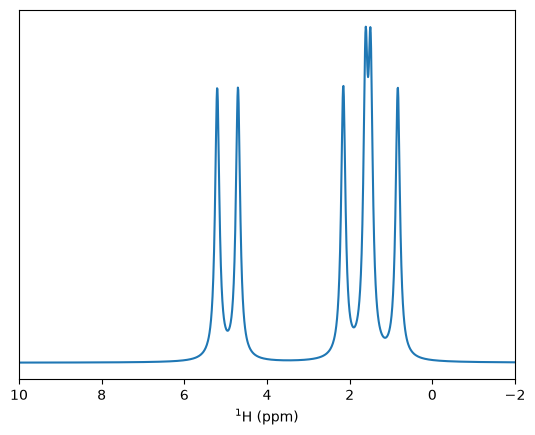

In [ ]:
import matplotlib.pyplot as plt
from ase.io import read
from soprano.calculate.nmr.simpson import write_spinsys

from simpyson import simulate_spectrum

atoms = read("ethanol.magres")
hydrogens = atoms[[a.index for a in atoms if a.symbol == "H"]]
spinsys = write_spinsys(hydrogens, use_ms=True, grad={"H": -1}, ref={"H": 31.7})

# A coarser powder average than the default: plenty for 1H, and much faster
spectrum = simulate_spectrum(spinsys, crystal_file="rep100", gamma_angles=6)

plt.plot(spectrum.spe["ppm"], spectrum.spe["real"])
plt.xlim(10, -2)
plt.xlabel("$^1$H (ppm)")
plt.yticks([])
plt.show()

`spectrum` is a [`Simpy`][simpyson.simpy.Simpy] object, the same type that `read_simp` returns, so everything in [Analyse SIMPSON output](01_reading_files.ipynb) applies: `spectrum.spe`, `spectrum.spe`, `spectrum.fid` and `spectrum.write(...)`.

What `write_spinsys` arguments mean:

| Argument | Meaning |
|---|---|
| `use_ms=True` | Include the chemical shift interaction from the magnetic shielding tensors in the file (`ms_tag=ms` is the default). |
| `ref={"H": 31.7}` | Reference shielding $\sigma_\mathrm{ref}$ in ppm for each element, see [Shielding to chemical shift](#shielding-to-chemical-shift). |
| `grad={"H": -1}` | Gradient $m$ of the shielding-to-shift conversion, close to $-1$. |
| `q_order=2` | Add quadrupolar interactions from the electric field gradient tensor, to second order. Needed for quadrupolar nuclei (spin > 1/2). |

The spin system only contains the interactions you request. In this example, chemical shifts of six independent <sup>1</sup>H, one resonance per H atom of ethanol. Dipolar couplings (`dip_sel`) and J couplings are not included.

## What `simulate_spectrum` does by default

Everything you do not specify is filled in from a set of defaults. To see exactly what was sent to SIMPSON, keep the input file with `filepath=` and `delete_files=False`, then print its `par` block:

In [3]:
spectrum = simulate_spectrum(
    spinsys,
    crystal_file="rep100",
    gamma_angles=6,
    filepath="ethanol.in",
    delete_files=False,
)

text = Path("ethanol.in").read_text()
print(text[text.index("par {") : text.index("proc pulseq")])

par {
   crystal_file         rep100
   detect_operator      Inp
   gamma_angles         6
   method               direct
   np                   4096
   proton_frequency     800000000.0
   spin_rate            30000.0
   start_operator       Inx
   sw                   30000.0
   verbose              0
   variable num_channels    1
   variable offset          2415.900349026749
   variable tsw             1e6/sw
   variable ref             -2415.900349026749
}





| Parameter | Default | Meaning |
|---|---|---|
| `proton_frequency` | `800e6` | <sup>1</sup>H Larmor frequency in **Hz** corresponding to 18.8 T. |
| `spin_rate` | `30e3` | MAS rate in Hz. `0` means a static sample. |
| `crystal_file` | `'rep2000'` | Powder average (SIMPSON crystal file). More orientations give a smoother lineshape. |
| `gamma_angles` | `16` | Number of $\gamma$ angles in the powder average (set to `1` automatically when `spin_rate=0`). |
| `np` | `4096` | Number of acquisition points. |
| `start_operator` | `'Inx'` | Starting density matrix: transverse magnetisation of all `n` spins. |
| `detect_operator` | `'Inp'` | Detected operator: all transverse magnetisation. Becomes `'Inc'` for quadrupolar nuclei, see below. |
| `method` | `'direct'` | SIMPSON propagation method. |
| `lb` | `100` | Exponential line broadening in Hz. |
| `zerofill` | `4096` | Zero-filled size before the Fourier transform (equal to `np`, so no interpolation). |
| `pulse_sequence` | `'no_pulse'` | Acquire only, starting from `start_operator`, xy-plane. |
| `sw` | estimated | Spectral width in Hz, see below. |

Any of these can be overridden with a keyword argument. Anything else you pass (for example `out_name`, `gauss_lb` or a `variable_...` parameter) is handed on to [`SimpCalc`][simpyson.calculator.SimpCalc].

!!! warning "Pass `proton_frequency` in Hz"
    The value is written into the SIMPSON input unchanged. A string such as `'400MHz'` is accepted when converting to ppm but makes SIMPSON stop with `invalid bareword "MHz"`, so use `400e6`.

## Automatic choices

Three things are worked out from the spin system, so that the peaks sit in the middle of the spectrum without you computing anything.

| What | How it is chosen |
|---|---|
| **Spectral width** `sw` | Twice the spread of the isotropic shifts (at least 10 ppm), rounded **up** to a whole multiple of `spin_rate` for MAS, so spinning sidebands fold onto the peaks. With a `quadrupole` interaction and the central transition detected (`Inc`), it is $C_Q^2/\nu_\mathrm{L}$ instead (the second-order broadening); with only quadrupolar interactions and no shifts it uses the same formula, or $2.5\,C_Q$ when not detecting the central transition. |
| **Carrier** `variable_offset` and **reference** `variable_ref` | The carrier is put at the centre of the shift range and the reference is set so that the axis reads in Hz relative to the transmitter frequency. This is why a single peak at 100 ppm is still centred. |
| **Detected operator** | `Inc` (central transition) for any quadrupolar nucleus with spin = n/2, where n=1, 3, 5, 7, and 9, unless you specify a diferent `detect_operator`. |

If the spin system has neither `shift` nor `quadrupole` lines, there is nothing to estimate from and you must pass `sw` yourself.

The cell below runs four tiny simulations and prints what was chosen for each:

In [4]:
def chosen(spinsys, **kwargs):
    """Run a simulation, keep the input, and report the automatic choices."""
    simulate_spectrum(spinsys, filepath="auto.in", delete_files=False, **kwargs)
    par = Path("auto.in").read_text().split("par {")[1].split("}")[0]
    keys = (
        "detect_operator",
        "gamma_angles",
        "spin_rate",
        "sw ",
        "variable offset",
        "variable ref",
    )
    return "\n".join(
        line.strip() for line in par.splitlines() if line.strip().startswith(keys)
    )


two_sites = (
    "channels 13C\nnuclei 13C 13C\nshift 1 50p 0 0 0 0 0\nshift 2 150p 0 0 0 0 0\n"
)
one_quad = (
    "channels 27Al\nnuclei 27Al\nshift 1 10p 0 0 0 0 0\nquadrupole 1 2 4e6 0.2 0 0 0\n"
)

print("13C, 50 and 150 ppm, 30 kHz MAS:\n" + chosen(two_sites))
print("\nSame, static (spin_rate=0):\n" + chosen(two_sites, spin_rate=0))
print("\n27Al, CQ = 4 MHz, central transition:\n" + chosen(one_quad))
print(
    "\nSame, but detect_operator='Inp' is given:\n"
    + chosen(one_quad, detect_operator="Inp")
)

13C, 50 and 150 ppm, 30 kHz MAS:
detect_operator      Inp
gamma_angles         16
spin_rate            30000.0
sw                   60000.0
variable offset          20120.296603532945
variable ref             -20120.296603532945



Same, static (spin_rate=0):
detect_operator      Inp
gamma_angles         1
spin_rate            0
sw                   40240.59320706589
variable offset          20120.296603532945
variable ref             -20120.296603532945



27Al, CQ = 4 MHz, central transition:
detect_operator      Inc
gamma_angles         16
spin_rate            30000.0
sw                   90000.0
variable offset          2086.1887672083913
variable ref             -2086.1887672083913



Same, but detect_operator='Inp' is given:
detect_operator      Inp
gamma_angles         16
spin_rate            30000.0
sw                   30000.0
variable offset          2086.1887672083913
variable ref             -2086.1887672083913


Reading the output: for the two <sup>13</sup>C sites, 100 ppm is 20.1 kHz at this field, twice that is 40.2 kHz, which rounds up to 60 kHz (two spinning rates); the carrier sits at 100 ppm. In the static case there is no rounding and `gamma_angles` drops to 1. For <sup>27</sup>Al the width follows $C_Q^2/\nu_\mathrm{L}$ (about 77 kHz, rounded up to 90 kHz), while giving `detect_operator='Inp'` returns the width to the shift-based estimate.

## Overriding the defaults

Pass any parameter as a keyword. Here, a lower field, faster spinning, narrower lines and interpolation by zero-filling:

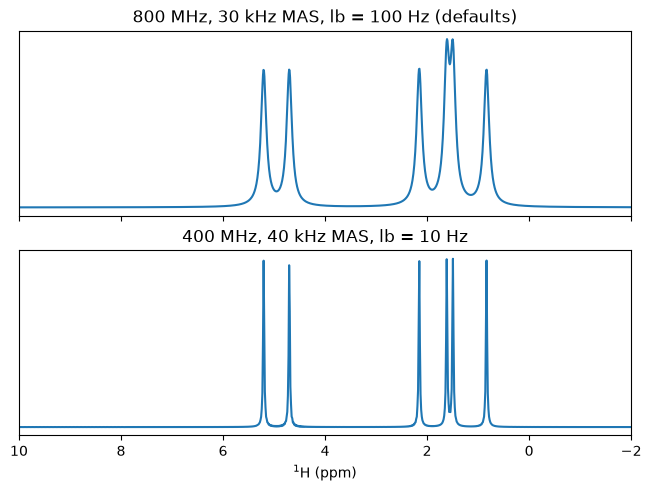

In [ ]:
default = simulate_spectrum(spinsys, crystal_file="rep100", gamma_angles=6)
custom = simulate_spectrum(
    spinsys,
    proton_frequency=400e6,  # Hz
    spin_rate=40e3,  # Hz
    lb=10,  # Hz
    zerofill=8192,
    crystal_file="rep100",
    gamma_angles=6,
)

fig, ax = plt.subplots(2, 1, sharex=True, constrained_layout=True)
ax[0].plot(default.spe["ppm"], default.spe["real"])
ax[0].set_title("800 MHz, 30 kHz MAS, lb = 100 Hz (defaults)")
ax[1].plot(custom.spe["ppm"], custom.spe["real"])
ax[1].set_title("400 MHz, 40 kHz MAS, lb = 10 Hz")
ax[1].set_xlim(10, -2)
ax[1].set_xlabel("$^1$H (ppm)")
for a in ax:
    a.set_yticks([])
plt.show()

`simulate_spectrum` derives `b0` and the nucleus for the ppm axis from `proton_frequency` and the first nucleus in the spin system, so `.spe` works without extra arguments.

For anything `simulate_spectrum` cannot express (a pulse sequence, cross polarisation, a different detection scheme), use [`SimpCalc`][simpyson.calculator.SimpCalc] directly, see [Custom simulations with SimpCalc](03_simulation_calculator.ipynb).

## Shielding to chemical shift

!!! warning "The usual DFT pitfall"
    DFT gives the magnetic shielding $\sigma$. SIMPSON needs the chemical shift $\delta$, the quantity you compare with experiment. Soprano converts one into the other with

    $$
    \delta = \frac{\sigma_\mathrm{ref} + m\,\sigma}{1 - \sigma_\mathrm{ref} \times 10^{-6}}
    $$

    where $\sigma_\mathrm{ref}$ is `ref` and $m$ is `grad`. If you leave `ref` out, Soprano raises an warning. If you use a wrong value, the spectrum is shifted by the same amount without any warning.

    - `ref` is **specific to your calculation** (code, functional, pseudopotentials, geometry) and to the nucleus. A value taken from a different setup shifts every peak.
    - `grad` is normally close to $-1$. Soprano warns for values outside $-1.5$ to $-0.5$.
    - The two values on this page (`31.7` for <sup>1</sup>H in ethanol; <sup>31</sup>P and <sup>27</sup>Al for AlPO-14 below) belong to the calculations in the example files. Do not reuse them for your own data.
    - Check the result against something you know: a reference compound computed with the same settings, or a peak position from experiment.

## VASP calculations

A VASP `OUTCAR` stores the shielding and electric field gradient in units that Soprano and SIMPSON cannot use directly, and ASE does not attach them to the structure. [`read_vasp`][simpyson.converter.read_vasp] parses the file and returns an ASE `Atoms` object with the `ms` and `efg` arrays, just like a `.magres` file:

In [6]:
from simpyson.converter import read_vasp

vasp = read_vasp("AlPO-14.OUTCAR", format="vasp-out")

print("Magnetic shielding tensor of the first atom:")
print(vasp.arrays["ms"][0])
print("\nElectric field gradient tensor of the first atom:")
print(vasp.arrays["efg"][0])

Magnetic shielding tensor of the first atom:
[[513.46414237  10.495471    -1.140594  ]
 [ 18.453975   526.66315637 -13.976764  ]
 [  1.644529    -6.971756   503.19928237]]

Electric field gradient tensor of the first atom:
[[ 0.01443807 -0.07187135  0.01989223]
 [-0.07187135 -0.06324762  0.05085742]
 [ 0.01989223  0.05085742  0.04881983]]


From here the workflow is the same as for CASTEP: select atoms, call `write_spinsys` with `ref` and `grad`, then `simulate_spectrum`.

## Large or quadrupolar systems

AlPO-14 contains eight <sup>27</sup>Al and eight <sup>31</sup>P sites per cell. SIMPSON builds one density matrix for the whole spin system, and its dimension is the product of the number of states, 2I+1, of every nucleus. For eight <sup>27</sup>Al (I = 5/2, six states each) this gives $6^8 \approx 1.7$ million, which is not computable in most machines. Eight <sup>31</sup>P, which is much smaller, but with the default powder average (rep2000, 16 gamma angles) still requires some compute time and memory.

When the sites do not interact (no dipolar or J couplings in the spin system, as here), you do not need to simulate them together. Simulate **one site at a time** and add the spectra: the sum is the same spectrum for a fraction of the cost.

The function below does that for any element of a structure. For the quadrupolar <sup>27</sup>Al, `q_order=2` adds the second-order quadrupolar interaction, and `simulate_spectrum` automatically detects the central transition (`Inc`) and sizes the spectral width from $C_Q$.

In [7]:
from simpyson.utils import add_spectra


def site_by_site(atoms, element, ref, spinsys_kwargs=None, **kwargs):
    """Simulate each atom of one element separately and sum the spectra."""
    spectra = []
    for index in [a.index for a in atoms if a.symbol == element]:
        spinsys = write_spinsys(
            atoms[[index]],
            use_ms=True,
            grad={element: -1},
            ref={element: ref},
            **(spinsys_kwargs or {}),
        )
        spectra.append(simulate_spectrum(spinsys, **kwargs))
    return add_spectra(spectra)


castep = read("AlPO-14.magres")

p_castep = site_by_site(castep, "P", ref=283.839, lb=200)
p_vasp = site_by_site(vasp, "P", ref=294.50, lb=200)
al_castep = site_by_site(
    castep, "Al", ref=538.78, spinsys_kwargs={"q_order": 2}, lb=200
)
al_vasp = site_by_site(vasp, "Al", ref=542.96, spinsys_kwargs={"q_order": 2}, lb=200)

Soprano can print a warning for some quadrupolar sites, when the computed EFG tensors are not exactly traceless, and Soprano sorts the eigenvalues by absolute value anyway.

`add_spectra` sums the spectra on a common frequency axis and returns a new `Simpy` object. The `ref` values differ between CASTEP and VASP because each code has its own absolute shielding scale. Comparing the two spectra is a quick check of how much your result depends on the code:

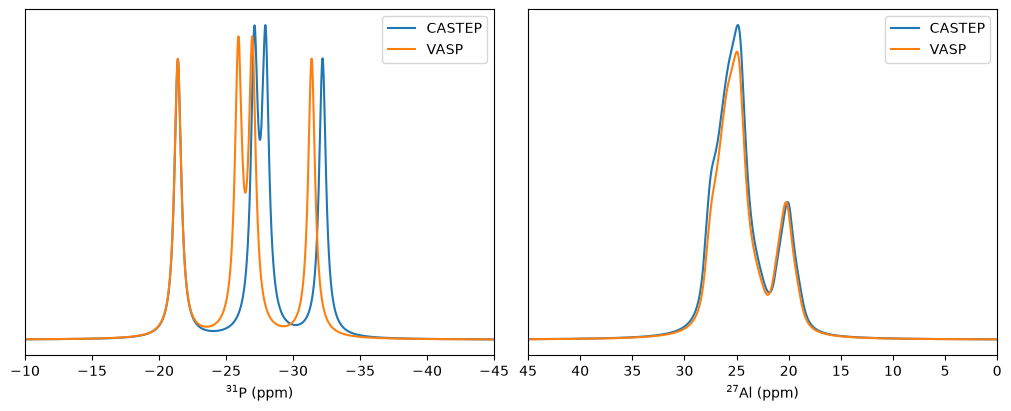

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

ax[0].plot(p_castep.spe["ppm"], p_castep.spe["real"], label="CASTEP")
ax[0].plot(p_vasp.spe["ppm"], p_vasp.spe["real"], label="VASP")
ax[0].set_xlabel("$^{31}$P (ppm)")
ax[0].set_xlim(-10, -45)

ax[1].plot(al_castep.spe["ppm"], al_castep.spe["real"], label="CASTEP")
ax[1].plot(al_vasp.spe["ppm"], al_vasp.spe["real"], label="VASP")
ax[1].set_xlabel("$^{27}$Al (ppm)")
ax[1].set_xlim(45, 0)

for a in ax:
    a.set_yticks([])
    a.legend()
plt.show()

### The same thing with `SimpCalc`

`simulate_spectrum` is a thin layer over [`SimpCalc`][simpyson.calculator.SimpCalc]. If you want to fix every setting yourself, or keep the SIMPSON input file to run on a cluster, build the calculation explicitly. This is one <sup>27</sup>Al site with all parameters spelled out (note that `SimpCalc` has no defaults for these and raises an error if one is missing):

In [9]:
from simpyson import SimpCalc

al_index = [a.index for a in castep if a.symbol == "Al"][0]
al_spinsys = write_spinsys(
    castep[[al_index]],
    use_ms=True,
    grad={"Al": -1},
    ref={"Al": 538.78},
    q_order=2,
)

calc = SimpCalc(
    spinsys=al_spinsys,
    pulse_sequence="no_pulse",
    proton_frequency=800e6,
    spin_rate=40e3,
    start_operator="Inx",
    detect_operator="Inc",
    crystal_file="rep168",
    gamma_angles=6,
    method="direct",
    np=2048,
    sw=20e3,
    verbose=0,
    lb=200,
    zerofill=4096,
)

calc.save(
    "castep_sim_al_0.in"
)  # SIMPSON input, ready to run with `simpson castep_sim_al_0.in`
single_site = calc.run()  # or run it from Python and read the result

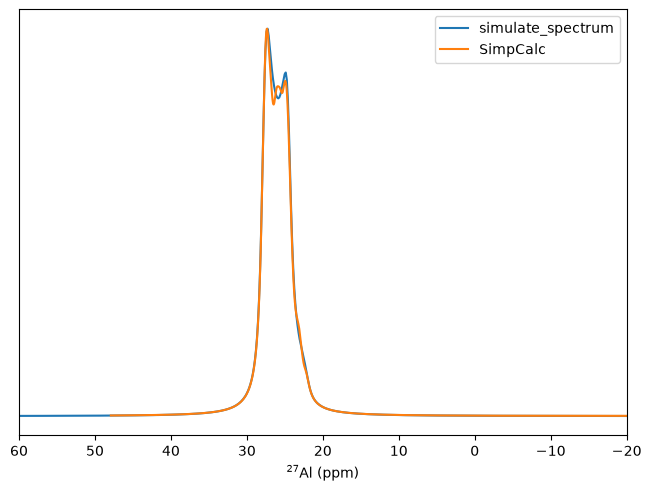

In [ ]:
site = simulate_spectrum(al_spinsys, lb=200)  # same site, simulate_spectrum defaults

fig, ax = plt.subplots(constrained_layout=True)
ax.plot(
    site.spe["ppm"],
    site.spe["real"] / site.spe["real"].max(),
    label="simulate_spectrum",
)
ax.plot(
    single_site.spe["ppm"],
    single_site.spe["real"] / single_site.spe["real"].max(),
    label="SimpCalc",
)
ax.set_xlim(60, -20)
ax.set_xlabel("$^{27}$Al (ppm)")
ax.set_yticks([])
ax.legend()
plt.show()

The two routes give the same lineshape. `SimpCalc` leaves the carrier at 0 Hz unless you set `variable_offset` and `variable_ref` (as `simulate_spectrum` does for you), so with a narrow `sw` the peak can sit away from the centre of the window.